# 06 - Quantization & Latency (RQ1: Real-time / Lightweight)

Uses your trained `model23/video_model.pth`. Measures the accuracy-vs-efficiency trade-off:
1. **FP32 baseline** - accuracy, model size, CPU latency (ms/clip), throughput (FPS).
2. **INT8 post-training static quantization** (PTQ) of the ResNet backbone - same metrics.
3. **Comparison table + charts** showing speed-up and size reduction at minimal accuracy cost.

Latency is measured on **CPU** (the laptop-deployment target from the proposal). A GPU is only used to speed up the accuracy sweep. Saves metrics + figure to `model23`.

In [1]:
import torch, os
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
print('CPU threads:', torch.get_num_threads())
!pip install -q opencv-python-headless gdown

CUDA available: True
GPU: NVIDIA L4
Drive ready: True
CPU threads: 6


In [2]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
VIDEO_CKPT  = MODELS + '/video_model.pth'
GDRIVE_FILE_ID = ''
EXTRACT_DIR = '/content/data'

NUM_FRAMES = 16
IMG        = 224
BATCH      = 8
SEED       = 42
ACC_SUBSET = 200
LAT_RUNS   = 30
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

import os
print('Video model:', VIDEO_CKPT, '-> exists:', os.path.exists(VIDEO_CKPT))

Video model: /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth -> exists: True


In [3]:
import os, json, glob, zipfile, shutil, copy, time
import cv2, numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

np.random.seed(SEED); torch.manual_seed(SEED)
GPU = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = [z for p in (DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip') for z in glob.glob(p)]
    zips = [z for z in zips if os.path.exists(z)]
    if not zips:
        import gdown
        outp = '/content/DATASET2.zip'
        if not os.path.exists(outp):
            gdown.download(id=GDRIVE_FILE_ID, output=outp, quiet=False)
        if os.path.exists(outp) and os.path.getsize(outp) > 1000000:
            zips = [outp]
    if zips:
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('DATASET_DIR =', DATASET_DIR)

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        base = models.resnet18(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b*t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def load_frames(path, n=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames')
    frames = []
    for i in np.linspace(0, total-1, n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < n: frames.append(frames[-1].copy() if frames else np.zeros((IMG,IMG,3),np.uint8))
    return frames[:n]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size/h, size/w); nh, nw = int(h*s), int(w*s)
    r = cv2.resize(img, (nw, nh)); c = np.zeros((size,size,3),np.uint8); y, x = (size-nh)//2, (size-nw)//2; c[y:y+nh, x:x+nw] = r; return c
def clip_tensor(path):
    fr = load_frames(path)
    return torch.stack([_norm(torch.from_numpy(letterbox(f).astype(np.float32)/255.0).permute(2,0,1)) for f in fr])
class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try: return clip_tensor(row.file_path), int(row.label_id)
        except Exception: return torch.zeros(NUM_FRAMES,3,IMG,IMG), int(row.label_id)
def build_index(rootdir):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(rootdir, folder)
        if not os.path.isdir(p): continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'group_id': gid})
    return pd.DataFrame(rows)
def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val+test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtmp = df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test/(val+test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return df.iloc[tr].reset_index(drop=True), dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)

model = TemporalPoolingResNet().to(GPU)
ck = torch.load(VIDEO_CKPT, map_location=GPU)
model.load_state_dict(ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck)
model.eval()

_, _, df_test = group_split(build_index(DATASET_DIR))
acc_df = df_test.sample(n=min(ACC_SUBSET, len(df_test)), random_state=SEED).reset_index(drop=True)
print('test clips:', len(df_test), '| accuracy-comparison subset:', len(acc_df))

def accuracy_on(m, dframe, device):
    m = (m.to(device) if device == 'cuda' else m.cpu()).eval()
    loader = DataLoader(VideoClipDataset(dframe), batch_size=BATCH)
    P, L = [], []
    with torch.no_grad():
        for x, y in loader:
            out = m(x.to(device) if device == 'cuda' else x)
            P += out.argmax(1).cpu().tolist(); L += y.tolist()
    return accuracy_score(L, P), f1_score(L, P, average='macro')

def cpu_latency(m, clip_cpu, runs=LAT_RUNS, warmup=5):
    m = m.cpu().eval()
    with torch.no_grad():
        for _ in range(warmup): m(clip_cpu)
        t0 = time.time()
        for _ in range(runs): m(clip_cpu)
    return (time.time() - t0) / runs

def size_mb(m, path):
    torch.save(m.state_dict(), path)
    return os.path.getsize(path) / 1e6

example_clip = clip_tensor(df_test.iloc[0].file_path).unsqueeze(0)
print('defs ready; example clip', tuple(example_clip.shape))

DATASET_DIR = /content/data
test clips: 732 | accuracy-comparison subset: 200
defs ready; example clip (1, 16, 3, 224, 224)


In [4]:
acc_dev = 'cuda' if torch.cuda.is_available() else 'cpu'
fp32_acc, fp32_f1 = accuracy_on(model, acc_df, acc_dev)
fp32_size = size_mb(model, '/content/fp32.pth')
fp32_lat = cpu_latency(model, example_clip)

print('FP32  | acc %.4f  macro-F1 %.4f  | size %.1f MB  | CPU %.1f ms/clip  (%.1f clips/s, %.0f frames/s)'
      % (fp32_acc, fp32_f1, fp32_size, fp32_lat*1000, 1.0/fp32_lat, NUM_FRAMES/fp32_lat))
model = model.to(GPU)

FP32  | acc 0.9300  macro-F1 0.9237  | size 44.8 MB  | CPU 139.7 ms/clip  (7.2 clips/s, 115 frames/s)


In [5]:
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx

int8_model = None
try:
    backbone = copy.deepcopy(model.features).cpu().eval()
    qmap = get_default_qconfig_mapping('x86')
    prepared = prepare_fx(backbone, qmap, torch.randn(1, 3, IMG, IMG))
    with torch.no_grad():
        for _, row in df_test.iloc[:8].iterrows():
            prepared(clip_tensor(row.file_path))
    q_backbone = convert_fx(prepared)
    int8_model = copy.deepcopy(model).cpu().eval()
    int8_model.features = q_backbone
    print('INT8 static quantization: OK')
except Exception as e:
    print('INT8 static PTQ failed:', repr(e))

if int8_model is not None:
    int8_acc, int8_f1 = accuracy_on(int8_model, acc_df, 'cpu')
    int8_size = size_mb(int8_model, '/content/int8.pth')
    int8_lat = cpu_latency(int8_model, example_clip)
    print('INT8  | acc %.4f  macro-F1 %.4f  | size %.1f MB  | CPU %.1f ms/clip  (%.1f clips/s, %.0f frames/s)'
          % (int8_acc, int8_f1, int8_size, int8_lat*1000, 1.0/int8_lat, NUM_FRAMES/int8_lat))

/tmp/ipykernel_44123/1502056380.py:9: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(backbone, qmap, torch.randn(1, 3, IMG, IMG))
/usr/local/lib/python3.12/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a f

INT8 static quantization: OK
INT8  | acc 0.9200  macro-F1 0.9169  | size 11.3 MB  | CPU 35.6 ms/clip  (28.1 clips/s, 449 frames/s)


       accuracy  macro_f1  size_mb  ms_per_clip  clips_per_s  frames_per_s
model                                                                     
FP32       0.93     0.924   44.789      139.728        7.157       114.508
INT8       0.92     0.917   11.310       35.648       28.052       448.837

Speed-up : 3.92x faster on CPU
Size     : 3.96x smaller (44.8 -> 11.3 MB)
Accuracy : 0.9300 -> 0.9200  (drop 0.0100)


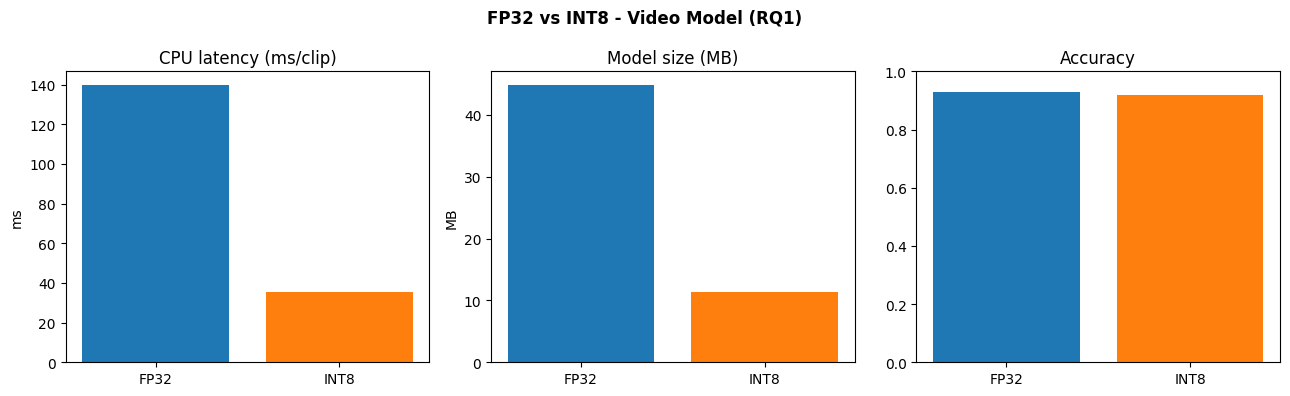

In [6]:
rows = [{'model': 'FP32', 'accuracy': fp32_acc, 'macro_f1': fp32_f1, 'size_mb': fp32_size,
         'ms_per_clip': fp32_lat*1000, 'clips_per_s': 1.0/fp32_lat, 'frames_per_s': NUM_FRAMES/fp32_lat}]
if int8_model is not None:
    rows.append({'model': 'INT8', 'accuracy': int8_acc, 'macro_f1': int8_f1, 'size_mb': int8_size,
                 'ms_per_clip': int8_lat*1000, 'clips_per_s': 1.0/int8_lat, 'frames_per_s': NUM_FRAMES/int8_lat})
tab = pd.DataFrame(rows).set_index('model')
print(tab.round(3).to_string())

if int8_model is not None:
    print()
    print('Speed-up : %.2fx faster on CPU' % (fp32_lat / int8_lat))
    print('Size     : %.2fx smaller (%.1f -> %.1f MB)' % (fp32_size/int8_size, fp32_size, int8_size))
    print('Accuracy : %.4f -> %.4f  (drop %.4f)' % (fp32_acc, int8_acc, fp32_acc - int8_acc))

    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    names = list(tab.index)
    ax[0].bar(names, tab['ms_per_clip'].values, color=['C0','C1']); ax[0].set_title('CPU latency (ms/clip)'); ax[0].set_ylabel('ms')
    ax[1].bar(names, tab['size_mb'].values, color=['C0','C1']); ax[1].set_title('Model size (MB)'); ax[1].set_ylabel('MB')
    ax[2].bar(names, tab['accuracy'].values, color=['C0','C1']); ax[2].set_title('Accuracy'); ax[2].set_ylim(0,1)
    plt.suptitle('FP32 vs INT8 - Video Model (RQ1)', fontweight='bold')
    plt.tight_layout(); plt.savefig(MODELS + '/quantization_comparison.png', dpi=150); plt.show()

In [7]:
out = {'fp32': rows[0]}
if int8_model is not None:
    out['int8'] = rows[1]
    out['speedup_cpu'] = fp32_lat / int8_lat
    out['size_reduction'] = fp32_size / int8_size
    out['accuracy_drop'] = fp32_acc - int8_acc
    torch.save(int8_model.state_dict(), MODELS + '/video_model_int8.pth')
    print('Saved INT8 model -> ' + MODELS + '/video_model_int8.pth')
out['acc_subset'] = int(len(acc_df))
out['cpu_threads'] = torch.get_num_threads()
json.dump(out, open(MODELS + '/quantization_metrics.json', 'w'), indent=2)
print('Saved quantization metrics + figure to', MODELS)

Saved INT8 model -> /content/drive/MyDrive/BadmintonFYP/model23/video_model_int8.pth
Saved quantization metrics + figure to /content/drive/MyDrive/BadmintonFYP/model23
